# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [1]:
# Preliminares
import pandas as pd
from src.cat_modeling import cargar_datos
from src.transform import categorizar_en_cuantiles
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    pintar_matriz_correlacion 
)

# Cargar fichero de precios
simbolo = 'NBIS'
intervalo = '1d'
df, cols_exclude = cargar_datos(simbolo=simbolo, intervalo=intervalo, leer_cols_exclude=True)
df_clean = df.drop(columns=cols_exclude)
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 456 entries, 2025-01-02 00:00:00-05:00 to 2026-10-27 00:00:00-04:00
Data columns (total 13 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Close_lag1_sma20_pct_diff_Close_lag1_sma50  456 non-null    float64
 1   Volume_lag1_pct_diff_Volume_lag1_sma20      456 non-null    float64
 2   Close_lag1_min20_pct_diff_Open              456 non-null    float64
 3   High_pct_diff_Open                          456 non-null    float64
 4   Low_pct_diff_Open                           456 non-null    float64
 5   Close_pct_diff_Open                         456 non-null    float64
 6   Low_lag1_pct_diff_Open                      456 non-null    float64
 7   Close_lag1_pct_diff_Open                    456 non-null    float64
 8   Close_lag1_sma50_pct_diff_Open              456 non-null    float64
 9   Daily_return_lag1                     

## Analisis de variables

In [2]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

In [3]:
# Descripcion de variables
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Close_lag1_sma20_pct_diff_Close_lag1_sma50,456.0,0.073583,0.135922,-0.230620,-0.008495,0.082054,0.176590,0.333299
Volume_lag1_pct_diff_Volume_lag1_sma20,456.0,0.067705,0.696726,-0.763229,-0.309533,-0.093240,0.227280,6.934859
Close_lag1_min20_pct_diff_Open,456.0,-0.201369,0.129182,-0.516163,-0.297639,-0.191085,-0.110430,0.082711
High_pct_diff_Open,456.0,0.040681,0.036555,0.000000,0.013424,0.029533,0.059357,0.214535
Low_pct_diff_Open,456.0,-0.039869,0.033189,-0.271343,-0.052984,-0.033970,-0.015924,0.000000
Close_pct_diff_Open,456.0,0.000882,0.052590,-0.221493,-0.030678,-0.002481,0.034232,0.155095
Low_lag1_pct_diff_Open,456.0,-0.042856,0.050088,-0.343621,-0.069383,-0.041367,-0.012693,0.171642
Close_lag1_pct_diff_Open,456.0,-0.003557,0.042166,-0.340947,-0.023737,-0.003923,0.018131,0.244478
Close_lag1_sma50_pct_diff_Open,456.0,-0.069540,0.220565,-0.426582,-0.252183,-0.104870,0.069845,0.681676
Daily_return_lag1,456.0,0.006243,0.070495,-0.374430,-0.035541,0.001669,0.043436,0.494224


In [4]:
# Asimetrias
mostrar_asimetrias(df_clean)

Volume_lag1_pct_diff_Volume_lag1_sma20        4.276542
High_pct_diff_Open                            1.499272
Daily_return_lag1                             0.847774
Close_lag1_sma50_pct_diff_Open                0.659647
Daily_return_lag1_var20_log                   0.492725
Close_lag1_max20_pct_diff_Open_yeo            0.073326
High_lag1_pct_diff_Open_yeo                   0.004283
Close_pct_diff_Open                          -0.031116
Close_lag1_min20_pct_diff_Open               -0.051438
Close_lag1_sma20_pct_diff_Close_lag1_sma50   -0.235817
Low_lag1_pct_diff_Open                       -0.517101
Close_lag1_pct_diff_Open                     -0.725875
Low_pct_diff_Open                            -1.731929


Cont


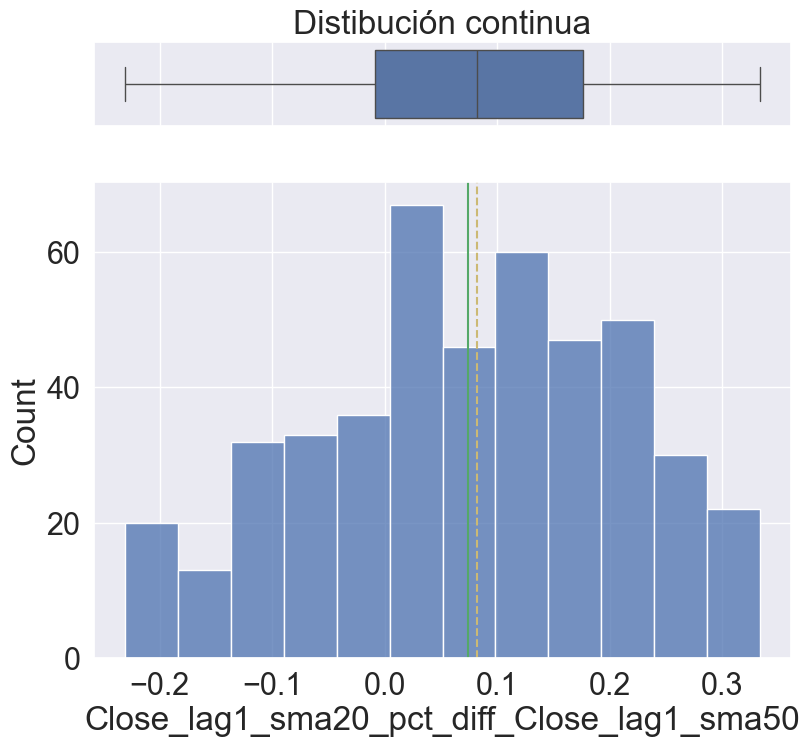

In [5]:
# Visualizar columna
col = 'Close_lag1_sma20_pct_diff_Close_lag1_sma50'
pintar_columna(df_clean[col])

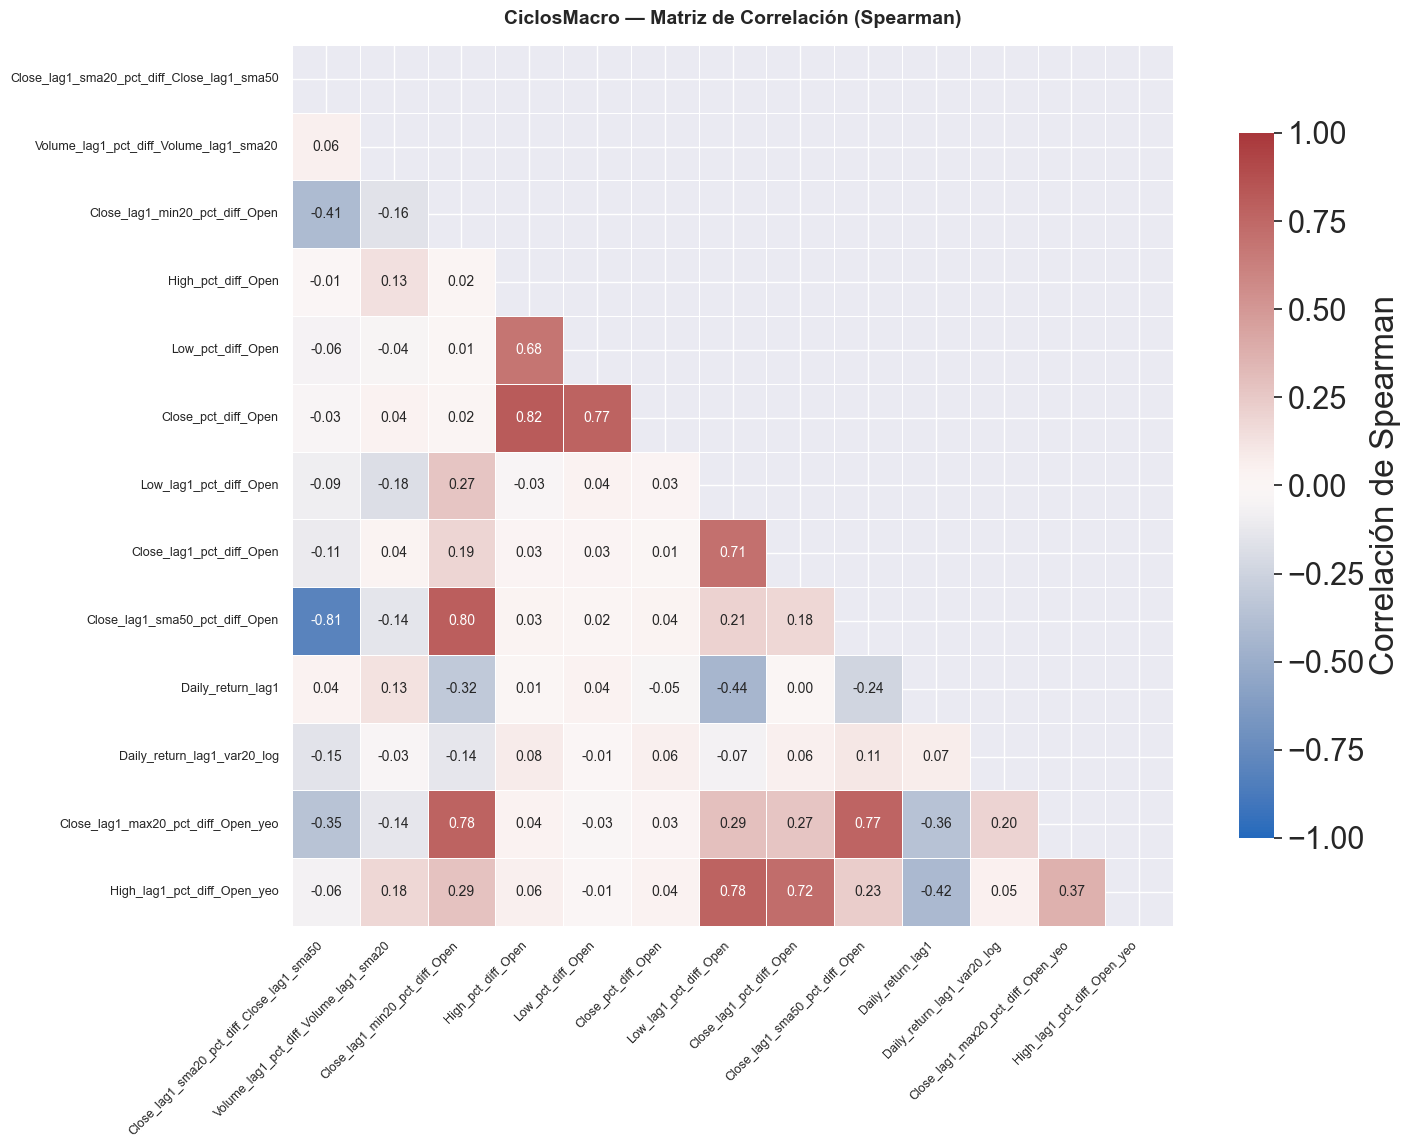

(                                            Close_lag1_sma20_pct_diff_Close_lag1_sma50  \
 Close_lag1_sma20_pct_diff_Close_lag1_sma50                                    1.000000   
 Volume_lag1_pct_diff_Volume_lag1_sma20                                        0.056983   
 Close_lag1_min20_pct_diff_Open                                               -0.408675   
 High_pct_diff_Open                                                           -0.006645   
 Low_pct_diff_Open                                                            -0.058613   
 Close_pct_diff_Open                                                          -0.034408   
 Low_lag1_pct_diff_Open                                                       -0.090371   
 Close_lag1_pct_diff_Open                                                     -0.114295   
 Close_lag1_sma50_pct_diff_Open                                               -0.809183   
 Daily_return_lag1                                                             0.039192   

In [6]:
# Matriz de correlacion
pintar_matriz_correlacion(df_clean)

* `Close_pct_diff_Open` presenta escasa correlacion con los predictores, siendo el posible label mas debil.

## Analisis de labels

In [7]:
posibles_labels = ['High_pct_diff_Open', 'Low_pct_diff_Open', 'Close_pct_diff_Open']

objetivo = 'High_pct_diff_Open'
objetivo_cat = f"{objetivo}_cat"

df_clean, tabla_bins = categorizar_en_cuantiles(
    df_clean, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=False
    )

print("\n--- Rangos por Categoría ---")
print(tabla_bins)


--- Rangos por Categoría ---
   categoria  lim_inferior  lim_superior
0          1      0.000000      0.018487
1          2      0.018487      0.046431
2          3      0.046431      0.214535


In [8]:
df_clean[objetivo_cat].value_counts()

High_pct_diff_Open_cat
1    152
2    152
3    152
Name: count, dtype: int64